In [1]:
import pickle
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


# Load the dataset
hard_elec = pd.read_excel('Composition_SFE_Dataset_old.xlsx')


#hard = pd.read_csv("hardness_composition_data.csv")
hard_elec_ip = hard_elec.drop(columns = ["SFE"])
hard_elec_op =hard_elec["SFE"]




hard_elec.head()


,Fe,Mn,Ni,Co,Cr,V,Al,SFE
0,0.142857,0.142857,0.142857,0.142857,0.142857,0.142857,0.142857,51.649535
1,0.202866,0.025391,0.365391,0.296460,0.054369,0.032077,0.023446,26.631791
2,0.182712,0.006847,0.510895,0.071240,0.161001,0.038695,0.028610,47.896873
3,0.035201,0.015630,0.724721,0.141416,0.030501,0.008102,0.044428,134.401773
4,0.227773,0.014224,0.531015,0.100751,0.063310,0.012472,0.050456,70.897057


In [4]:
import numpy as np
X = hard_elec_ip
y = hard_elec_op

In [5]:
import joblib

# 3. LOAD THE TRAINED STACKED SFE MODEL
# ===============================================
stacked_model = joblib.load("stacked_sfe_model.pkl")
print("Stacked SFE model loaded successfully!")

# Check a sample prediction
sample_pred = stacked_model.predict(X_sfe.iloc[0:1])
print("Sample prediction:", sample_pred)



Stacked SFE model loaded successfully!


NameError: name 'X_sfe' is not defined

In [6]:
df = pd.read_excel("Composition_SFE_Dataset_old.xlsx")

X_sfe = df.drop(columns=["SFE"])
y_sfe = df["SFE"]

print("Dataset loaded.")
print("Shape:", X_sfe.shape)
print(X_sfe.head())

# ===============================================
# 3. LOAD THE TRAINED STACKED SFE MODEL
# ===============================================
stacked_model = joblib.load("stacked_sfe_model.pkl")
print("Stacked SFE model loaded successfully!")

# Check a sample prediction
sample_pred = stacked_model.predict(X_sfe.iloc[0:1])
print("Sample prediction:", sample_pred)



Dataset loaded.
Shape: (426, 7)
         Fe        Mn        Ni        Co        Cr         V        Al
0  0.142857  0.142857  0.142857  0.142857  0.142857  0.142857  0.142857
1  0.202866  0.025391  0.365391  0.296460  0.054369  0.032077  0.023446
2  0.182712  0.006847  0.510895  0.071240  0.161001  0.038695  0.028610
3  0.035201  0.015630  0.724721  0.141416  0.030501  0.008102  0.044428
4  0.227773  0.014224  0.531015  0.100751  0.063310  0.012472  0.050456
Stacked SFE model loaded successfully!
Sample prediction: [51.0118968]


In [8]:
# ===============================================
# 4. BUILD SHAP EXPLAINER (MODEL-AGNOSTIC)
# ===============================================
import shap
# Wrap prediction into a safe function for SHAP
def sfe_model_predict(x):
    if isinstance(x, np.ndarray):
        x_df = pd.DataFrame(x, columns=X_sfe.columns)
    else:
        x_df = x
    return stacked_model.predict(x_df)

# Use Independent masker on the feature space
masker = shap.maskers.Independent(X_sfe)

# Build SHAP Explainer
explainer_sfe = shap.Explainer(
    sfe_model_predict,
    masker=masker
)

print("SHAP Explainer created.")



C:\Users\DEBS\anaconda3\envs\sfe_ml\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP Explainer created.


ExactExplainer explainer: 427it [02:50,  2.46it/s]                                                                                                                         


SHAP values computed.
SHAP shape: (426, 7)


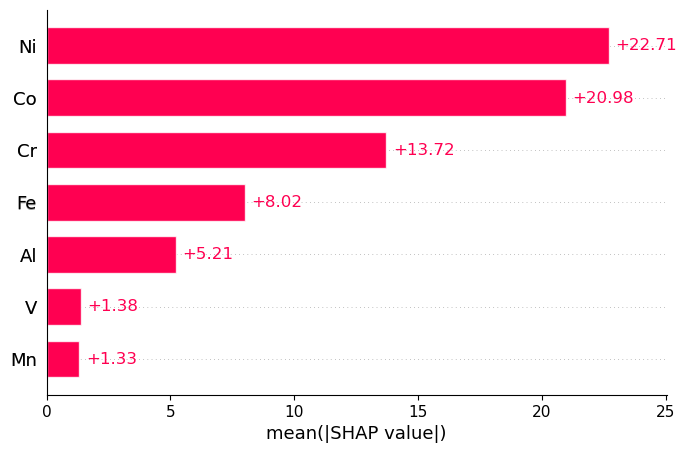

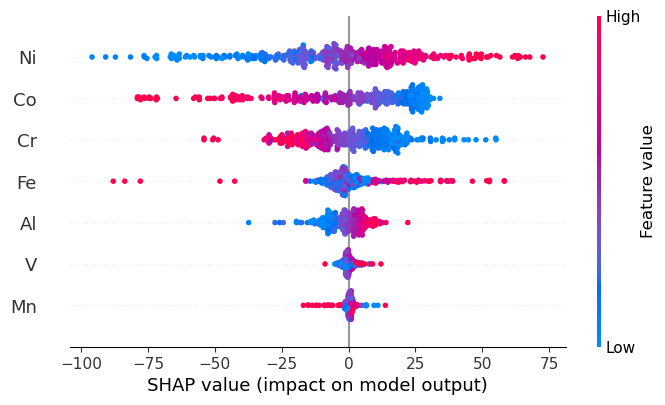

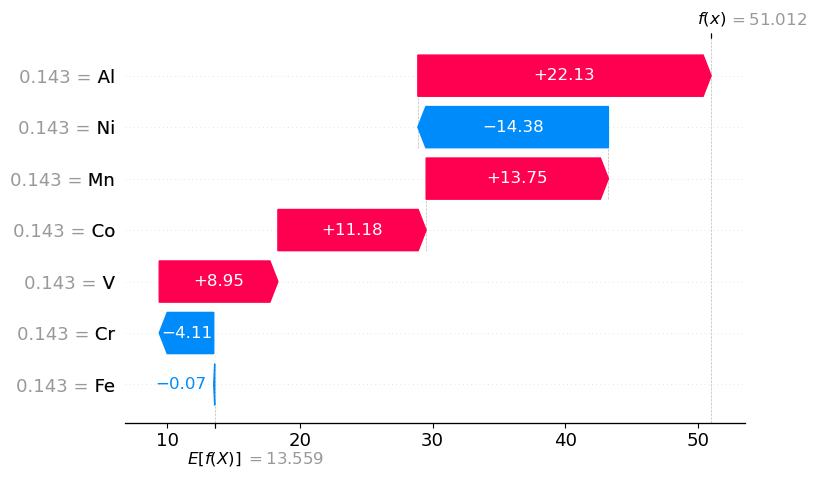

In [10]:
# ===============================================
# 5. COMPUTE SHAP VALUES
# ===============================================
# Can reduce samples for speed (e.g., X_sfe.sample(200))
shap_values_sfe = explainer_sfe(X_sfe)

print("SHAP values computed.")
print("SHAP shape:", shap_values_sfe.values.shape)

# ===============================================
# 6. GLOBAL SHAP PLOTS
# ===============================================

# --- Global Feature Importance (Bar Plot)
shap.plots.bar(shap_values_sfe)
plt.show()

# --- Beeswarm Plot (distribution of effects)
shap.plots.beeswarm(shap_values_sfe)
plt.show()

# --- Waterfall plot for the FIRST sample
shap.waterfall_plot(shap_values_sfe[0])
plt.show()



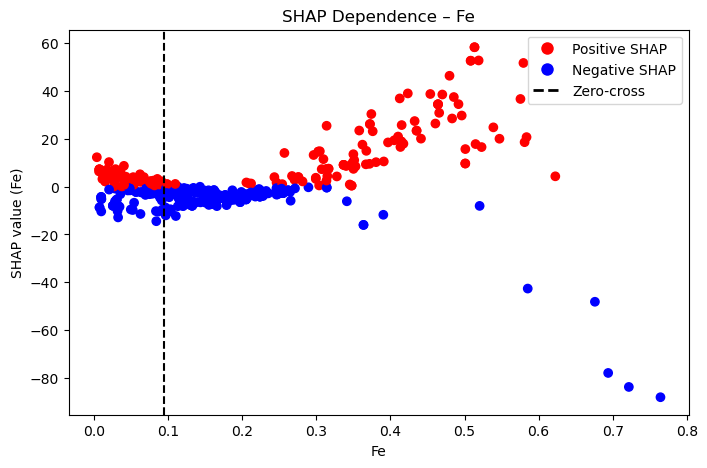

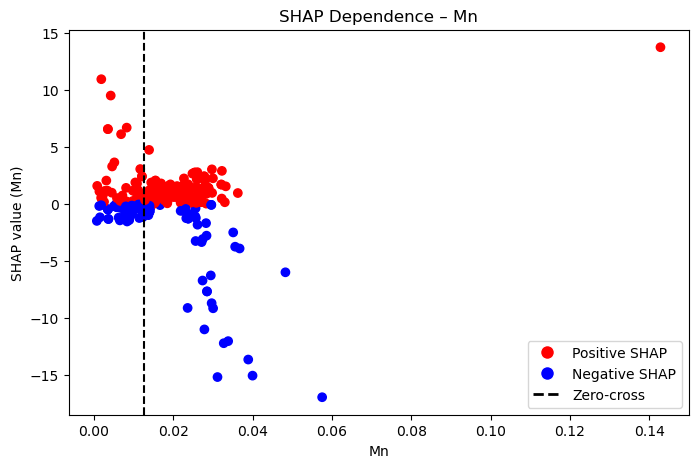

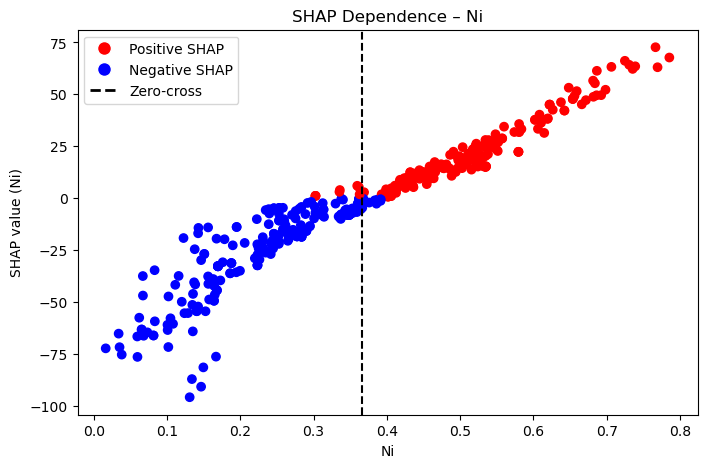

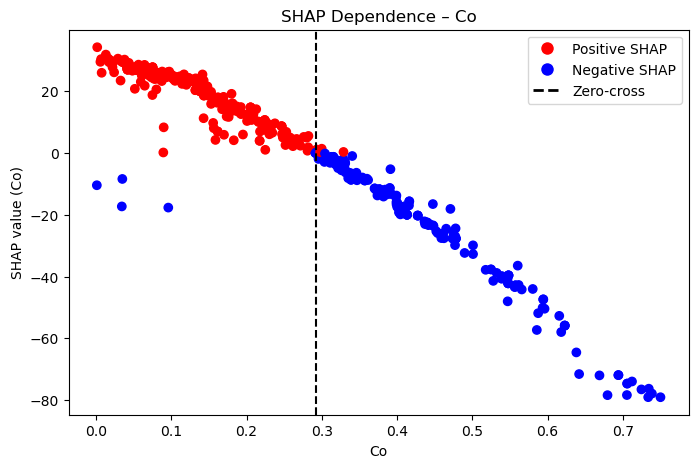

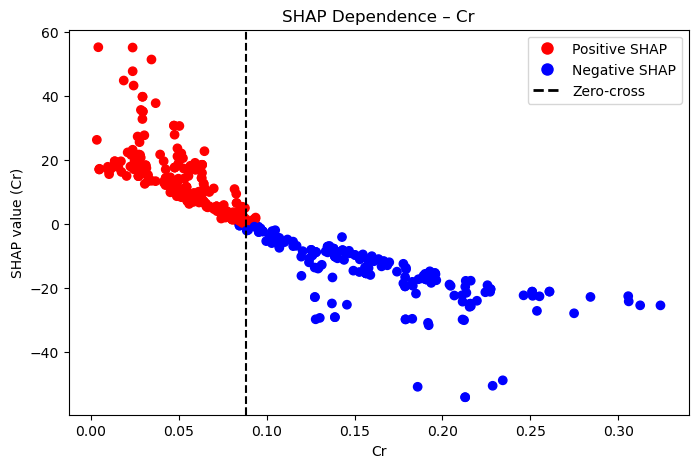

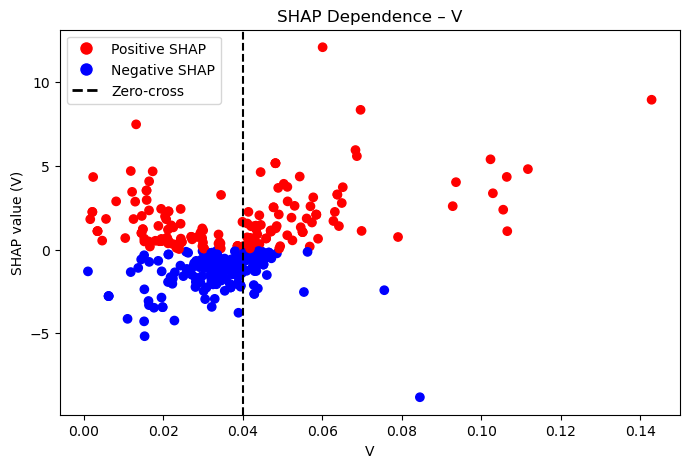

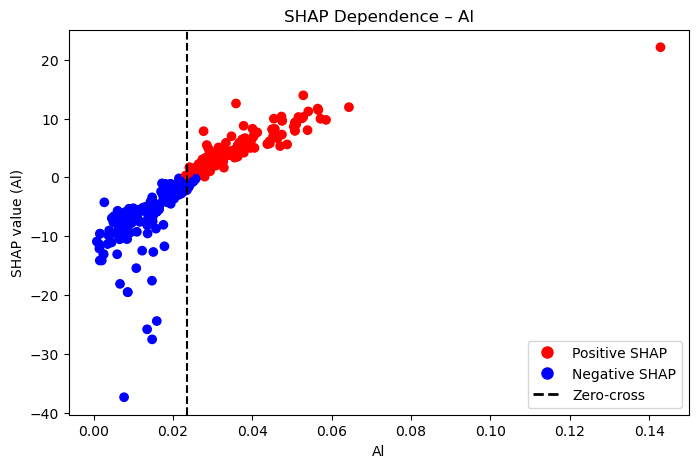

All SHAP analyses completed successfully!


In [11]:
# ===============================================
# 7. SHAP DEPENDENCE PLOTS FOR EACH FEATURE
# (same style as your hardness code)
# ===============================================
import matplotlib.pyplot as plt

def plot_shap_dependence_sfe(feature, shap_values, X):
    plt.figure(figsize=(8,5))

    # Extract SHAP values for a feature
    shap_vals_feature = shap_values[:, X.columns.get_loc(feature)].values

    # Color code: red = positive effect, blue = negative
    colors = ['red' if val >= 0 else 'blue' for val in shap_vals_feature]

    plt.scatter(X[feature], shap_vals_feature, c=colors)

    # Find the point closest to SHAP=0.0000001 (inflection point)
    idx = np.argmin(np.abs(shap_vals_feature - 0.0000001))
    x_cross = X[feature].iloc[idx]

    plt.axvline(x=x_cross, color="black", linestyle="--",
                label=f"Zero-cross at X={x_cross:.3f}")

    # Custom legend
    pos_legend = plt.Line2D([0], [0], marker='o', color='w',
                            markerfacecolor='red', markersize=10,
                            label='Positive SHAP')
    neg_legend = plt.Line2D([0], [0], marker='o', color='w',
                            markerfacecolor='blue', markersize=10,
                            label='Negative SHAP')
    cross_legend = plt.Line2D([0], [0], color='black', linestyle='--',
                              linewidth=2, label='Zero-cross')

    plt.legend(handles=[pos_legend, neg_legend, cross_legend])
    plt.xlabel(feature)
    plt.ylabel(f"SHAP value ({feature})")
    plt.title(f"SHAP Dependence – {feature}")
    plt.show()


# ---------- RUN DEPENDENCE PLOTS FOR ALL FEATURES ----------
for feature in X_sfe.columns:
    plot_shap_dependence_sfe(feature, shap_values_sfe, X_sfe)

print("All SHAP analyses completed successfully!")

In [6]:
!pip install scikit-learn==1.5.1

   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.0 MB 5.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.9/11.0 MB 7.6 MB/s eta 0:00:02
   --------------- ------------------------ 4.2/11.0 MB 6.8 MB/s eta 0:00:01
   -------------------- ------------------- 5.5/11.0 MB 6.7 MB/s eta 0:00:01
   ------------------------- -------------- 7.1/11.0 MB 6.9 MB/s eta 0:00:01
   ------------------------------- -------- 8.7/11.0 MB 7.0 MB/s eta 0:00:01
   ------------------------------------- -- 10.2/11.0 MB 7.1 MB/s eta 0:00:01
   ---------------------------------------- 11.0/11.0 MB 6.8 MB/s  0:00:01
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.7.2
    Uninstalling scikit-learn-1.7.2:
      Successfully uninstalled scikit-learn-1.7.2


  You can safely remove it manually.


In [7]:
import sklearn
print(sklearn.__version__)


1.7.2
